# Ноутбук 1. Обзор литературы

**Тема:** достать из описания товара характеристики (бренд, диагональ, разрешение и т. д.) и вернуть их как JSON.

Здесь: как искал статьи, что взял, что выкинул и что из этого следует для работы.

## Задача и запрос


## 1. Постановка задачи ВКР

**Тема:** реализация модели извлечения структурированных атрибутов товаров из их текстовых описаний.

**Формально.** Дано русскоязычное описание товара $x$ и схема категории $S = \{a_1,\dots,a_k\}$ (например, для мониторов: диагональ, разрешение, матрица, частота, интерфейсы). Нужно получить JSON $y = \{a_i: v_i\}$, где $v_i$ — значение из текста (с нормализацией единиц) или `null`, если атрибут в тексте не указан.

**Исследовательский вопрос.** Насколько хорошо универсальные LLM извлекают атрибуты из русскоязычных описаний товаров в режимах zero-shot и few-shot, и сохраняется ли качество при переходе от **синтетических** данных (на них подбираются промпты и примеры) к **реальным** карточкам магазина?

**Особенность постановки (отличие от примера в задании).** Задача — не классификация, а структурированная генерация. Поэтому вместо Macro-F1 и MCC основной метрикой будет F1 по парам «атрибут–значение», а к ней добавятся exact match по записи и доля невалидных JSON.


**Запрос для поиска:**
`("attribute value extraction" OR "product attribute extraction") AND (LLM OR "few-shot" OR "zero-shot" OR "synthetic data") AND (e-commerce OR product)`

In [1]:
import ssl, urllib.parse, urllib.request
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ONLINE = True
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 70, "display.width", 200)

# сертификаты: хранилище Windows (pip install truststore), иначе обычные
try:
    import truststore
    ctx = truststore.SSLContext(ssl.PROTOCOL_TLS_CLIENT)
except ImportError:
    ctx = ssl.create_default_context()

In [2]:
query = 'all:"attribute value extraction" AND (all:LLM OR all:"large language model")'
url = "https://export.arxiv.org/api/query?" + urllib.parse.urlencode({"search_query": query, "max_results": 50})
root = ET.fromstring(urllib.request.urlopen(url, timeout=30, context=ctx).read())
ns = {"a": "http://www.w3.org/2005/Atom"}
found = pd.DataFrame([{
    "title": " ".join(e.find("a:title", ns).text.split()),
    "date": e.find("a:published", ns).text[:10],
    "url": e.find("a:id", ns).text,
} for e in root.findall("a:entry", ns)])
found.to_csv(OUT / "arxiv_search.csv", index=False)
display(found)

,title,date,url
0,LLM-Ensemble: Optimal Large Language Model Ensemble Method for E-c...,2024-02-29,http://arxiv.org/abs/2403.00863v2
1,EIVEN: Efficient Implicit Attribute Value Extraction using Multimo...,2024-04-13,http://arxiv.org/abs/2404.08886v1
2,Self-Refinement Strategies for LLM-based Product Attribute Value E...,2025-01-02,http://arxiv.org/abs/2501.01237v2
3,AI-PAVE-Br: Leveraging Large Language Models for Enhanced Product ...,2026-06-23,http://arxiv.org/abs/2606.24655v1
4,ImplicitAVE: An Open-Source Dataset and Multimodal LLMs Benchmark ...,2024-04-24,http://arxiv.org/abs/2404.15592v2
5,Multi-Label Zero-Shot Product Attribute-Value Extraction,2024-02-13,http://arxiv.org/abs/2402.08802v1
6,MADIAVE: Multi-Agent Debate for Implicit Attribute Value Extraction,2025-10-07,http://arxiv.org/abs/2510.05611v2
7,Breaking the Autoregressive Chain: Hyper-Parallel Decoding for Eff...,2026-04-29,http://arxiv.org/abs/2604.26209v1
8,Visual Zero-Shot E-Commerce Product Attribute Value Extraction,2025-02-21,http://arxiv.org/abs/2502.15979v1
9,Correcting to Predict: Pseudo-Value Correction for Multimodal Attr...,2026-09-28,http://arxiv.org/abs/2609.34383v1


## Что взял и что выкинул

Нашёл 44 работы: 17 не открывал (отсеял по названию или оставил в запас), 27 посмотрел, 13 выкинул, 14 взял.

**Журнальные статьи (Q1/Q2).** Основной поиск почти не находил журналов: результаты были в основном с arXiv и из конференций. Задание требует среди источников конференции A/A*, журналы Q1 или открытые журналы, отечественные работы или препринты, поэтому позже добавил отдельные запросы с названиями журналов (`Expert Systems with Applications`, `Information Processing & Management`, `Knowledge-Based Systems`, `Information Sciences`, `Neurocomputing`, `Electronic Commerce Research`, `Decision Support Systems` и др.) и словами `journal article`. По ним найдены № 4 (ESWA) и № 8 (Electronics). Остальные результаты этих запросов разобраны в таблицах исключённых ниже. Они попали в обзор не из основного запроса, а из дополнительного. Квартили проверены по Scimago.

**Критерии включения:**
- [x] Тема: извлечение атрибутов из текста товара, либо метод, который прямо нужен протоколу (синтетические данные, адаптация LLM, модели).
- [x] Есть первоисточник, который удалось открыть и проверить.
- [x] Работа не отозвана.



**Критерии исключения:** отозвана; другая задача (сопоставление товаров, тренды моды); нет данных об авторах, дате или площадке; закрытые данные без возможности воспроизведения.

In [3]:
excluded = pd.read_excel("excluded.xlsx")
not_read = pd.read_excel("review.xlsx", sheet_name="не открывал")

In [4]:
excluded

,работа,почему выкинул,ссылка
0,Vikhr (MRL 2024),"статью отозвали, в таблице 6 ошибка",NaN
1,ruT5 / ruBERT (Zmitrovich и др.),"модели общего назначения, про атрибуты ничего",NaN
2,PAE,"извлекает из PDF с трендами моды, а не из описаний",NaN
3,"Habr, ecom.tech","про сопоставление товаров, не про извлечение",NaN
4,UIE (ACL 2022),"общее извлечение, не про товары",NaN
5,OA-Mine (WWW 2022),"атрибуты заранее не заданы, а у нас заданы",NaN
6,GPT-3 (NeurIPS 2020),"общий фон, few-shot смотрим в ExtractGPT",NaN
7,Parallel Decoding (Amazon),"нет даты и площадки, данные закрыты",NaN
8,Explicit Attribute Extraction in e-Commerce Search (ECNLP 2024),"извлекает из поисковых запросов, а не из описаний",https://aclanthology.org/2024.ecnlp-1.13/
9,Sabeh и др. Exploring LLMs for Product Attribute Value Identificat...,"промптинг LLaMA/Mistral для извлечения, близко к ExtractGPT и Brin...",https://arxiv.org/abs/2409.12695


## 14 источников

Колонки: задача, как устроено, на чём, метрики, есть ли код, минусы, что взять себе.

In [5]:
sources = pd.read_excel("review.xlsx")
sources

,№,статья,задача,как устроено,данные,метрики,код,минусы,что взять себе,ссылка
0,1,"OpenTag, KDD 2018",достать значения из текста,"BiLSTM-CRF + attention, активное обучение","Amazon.com: корм для собак, камеры, моющие средства",F-score 83% (заявлено),в статье не указан,"находит только куски текста, единицы не приводит",простая разметочная модель как baseline на русском,https://arxiv.org/abs/1806.01264
1,2,"AdaTag, ACL 2021","то же, но сразу много атрибутов",общий энкодер и свой декодер на каждый атрибут,"e-commerce набор Amazon, название не дано",Macro-P/R/F1 (точное совпадение значения),в статье не указан,нужна размеченная выборка,сравнить с одним промптом для LLM,https://aclanthology.org/2021.acl-long.362/
2,3,"MAVE, WSDM 2022",большой датасет,модель + датасет,"~2,2 млн товаров Amazon, 1257 категорий","Precision, Recall, F1 (усреднение не указано)",разметка и скрипты очистки открыты; лицензия CC BY-NC 4.0 (только ...,"английский; авторы ExtractGPT пишут, что в разметке есть ошибки","формат записей, тест на новых атрибутах",https://research.google/pubs/mave-a-product-dataset-for-multi-sour...
3,4,"Roy, Goyal, Pandey. Exploring generative frameworks for product at...","достать значение атрибута генерацией, а не разметкой токенов или в...",две постановки: (1) по названию и атрибуту сгенерировать значение;...,"AE-650K (AliExpress, Sports & Entertainment) и MAE; 28 тыс. и 78 т...","P, R, F1 по парам атрибут-значение, точное совпадение; генеративны...",обещан github.com/kalyani-roy/AVE (в статье 'will be available'),"размечены не все значения, верная генерация считается ошибкой; слу...",формулировка «название + атрибут → значение» и предупреждение про ...,https://doi.org/10.1016/j.eswa.2023.122850
4,5,"ExtractGPT, iiWAS 2024 (препринт 2023)","то же, но через LLM",промпт: описание атрибута + примеры значений + примеры разбора,"OA-Mine, AE-110K",F1 у GPT-4 около 85%,да: github.com/wbsg-uni-mannheim/extractgpt,"английский, платные модели",взять шаблон промпта,https://arxiv.org/abs/2310.12537
5,6,"Brinkmann и др., 2024 (препринт)",извлечь и привести к единому виду,zero-/few-shot GPT-3.5 и GPT-4,"WDC-PAVE: 565 карточек, 4687 пар",F1 около 91%,"да: github.com/wbsg-uni-mannheim/wdc-pave (где лежат данные, прове...",тяжелее всего перевод единиц; маленький набор,"отдельно считать ошибки с единицами (ГБ, Гц, дюймы)",https://arxiv.org/abs/2403.02130
6,7,"GAVEL, 2025","извлекать и обучаться на данных, дополненных LLM",генерация + LLM,">1000 атрибутов, 2000 категорий, тайский, вьетнамский, индонезийский","recall, F1, A/B-тест",-,"какие данные и модели, не сказано","обучать на данных, которые дополнила LLM",https://aclanthology.org/2025.knowledgenlp-1.6/
7,8,"Çiftlikçi и др., Electronics (MDPI) 2025, Q2 по Scimago (SJR 2025 ...",извлечение атрибутов из турецких карточек Trendyol,"Mistral + LoRA (rank 64, alpha 128) против RoBERTa","Trendyol, ~3 млн + ~867 тыс. записей, 700+ категорий и атрибутов, ...","P, R, F1; разница F1 от 3% считалась значимой",не указан,данные внутренние; описание DL-модели в статье непоследовательно,"LoRA на не-английском языке, ориентир гиперпараметров",https://www.mdpi.com/2079-9292/14/10/1930
8,9,"SynthIE, EMNLP 2023",синтетика для извлечения,"сначала готовая структура, потом LLM пишет по ней текст; на этом у...","1,8 млн синтетических примеров",micro/macro-F1 (+57 п.п. заявлено),-,другая область,генерировать описания по готовым атрибутам: разметка известна сразу,https://aclanthology.org/2023.emnlp-main.96/
9,10,"Controlled Product Generation, 2025 (препринт)",синтетические товары,LLM пишет товары по заданным атрибутам,синтетика + MAVE,"на MAVE 60,5% на синтетике и 60,8% на реальных; 2000 товаров оцени...",-,"препринт, английский",делать и примеры без части атрибутов (null),https://arxiv.org/abs/2601.04200


In [13]:
# запущено 14.10.2026
for i, u in sources["ссылка"].items():
    try:
        req = urllib.request.Request(u, headers={"User-Agent": "Mozilla/5.0"})
        print(i, urllib.request.urlopen(req, timeout=20, context=ctx).status, u)
    except Exception as e:
        print(i, e, u)

0 200 https://arxiv.org/abs/1806.01264
1 200 https://aclanthology.org/2021.acl-long.362/
2 200 https://research.google/pubs/mave-a-product-dataset-for-multi-source-attribute-value-extraction/
3 200 https://doi.org/10.1016/j.eswa.2023.122850
4 200 https://arxiv.org/abs/2310.12537
5 200 https://arxiv.org/abs/2403.02130
6 200 https://aclanthology.org/2025.knowledgenlp-1.6/
7 HTTP Error 403: Forbidden https://www.mdpi.com/2079-9292/14/10/1930
8 200 https://aclanthology.org/2023.emnlp-main.96/
9 200 https://arxiv.org/abs/2601.04200
10 200 https://arxiv.org/abs/2412.15115
11 200 https://aclanthology.org/2025.acl-demo.10/
12 200 https://arxiv.org/abs/2106.09685
13 200 https://arxiv.org/abs/2305.14314


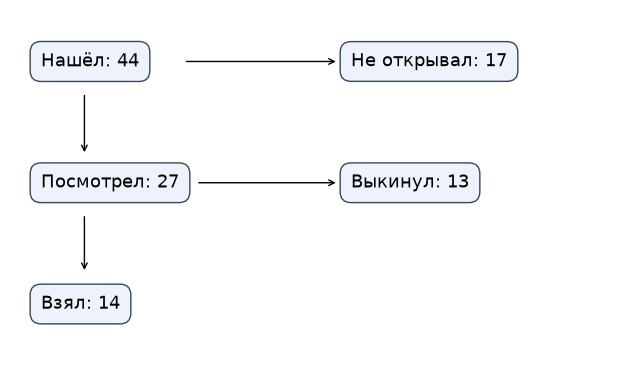

,работа,почему выкинул,ссылка
0,Vikhr (MRL 2024),"статью отозвали, в таблице 6 ошибка",NaN
1,ruT5 / ruBERT (Zmitrovich и др.),"модели общего назначения, про атрибуты ничего",NaN
2,PAE,"извлекает из PDF с трендами моды, а не из описаний",NaN
3,"Habr, ecom.tech","про сопоставление товаров, не про извлечение",NaN
4,UIE (ACL 2022),"общее извлечение, не про товары",NaN
5,OA-Mine (WWW 2022),"атрибуты заранее не заданы, а у нас заданы",NaN
6,GPT-3 (NeurIPS 2020),"общий фон, few-shot смотрим в ExtractGPT",NaN
7,Parallel Decoding (Amazon),"нет даты и площадки, данные закрыты",NaN
8,Explicit Attribute Extraction in e-Commerce Search (ECNLP 2024),"извлекает из поисковых запросов, а не из описаний",https://aclanthology.org/2024.ecnlp-1.13/
9,Sabeh и др. Exploring LLMs for Product Attribute Value Identificat...,"промптинг LLaMA/Mistral для извлечения, близко к ExtractGPT и Brin...",https://arxiv.org/abs/2409.12695


In [11]:
# схема отбора
total = len(sources) + len(excluded) + len(not_read)
read = len(sources) + len(excluded)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")
for x, y, t in [(0.05, 0.85, f"Нашёл: {total}"), (0.55, 0.85, f"Не открывал: {len(not_read)}"),
                (0.05, 0.50, f"Посмотрел: {read}"), (0.55, 0.50, f"Выкинул: {len(excluded)}"),
                (0.05, 0.15, f"Взял: {len(sources)}")]:
    ax.text(x, y, t, fontsize=13, va="center", bbox=dict(boxstyle="round,pad=0.6", fc="#eef3fb", ec="#34495e"))
for a, b in [((0.12, 0.76), (0.12, 0.58)), ((0.12, 0.41), (0.12, 0.24)), ((0.28, 0.85), (0.53, 0.85)), ((0.30, 0.50), (0.53, 0.50))]:
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->"))
fig.savefig(OUT / "prisma.png", dpi=150, bbox_inches="tight")
plt.show()
excluded

## 3. Отобранные источники

### A. Извлечение атрибутов: классика, данные, генеративные модели

**1. Zheng, Mukherjee, Dong, Li. OpenTag: Open Attribute Value Extraction from Product Profiles. KDD 2018.**
Извлечение как sequence tagging: BiLSTM + CRF + attention, без словарей и ручных признаков; active learning. Заявлено: новые значения находятся примерно по 150 размеченным примерам (в 3,3 раза меньше разметки), F-score 83%. Это точка отсчёта для supervised-подхода. [arXiv](https://arxiv.org/abs/1806.01264)

**2. Yan, Zalmout, Liang, Grant, Ren, Dong. AdaTag: Multi-Attribute Value Extraction from Product Profiles with Adaptive Decoding. ACL-IJCNLP 2021.**
Один общий энкодер и отдельный декодер на каждый атрибут, который генерируется на лету (гиперсеть + Mixture-of-Experts). Решает противоречие между «модель на каждый атрибут» и «одна модель на всё». [ACL Anthology](https://aclanthology.org/2021.acl-long.362/)

**3. Yang, Wang, Yu, Kulkarni, Sanghai, Shu, Elsas, Kanagal. MAVE: A Product Dataset for Multi-source Attribute Value Extraction. WSDM 2022.**
Около 2,2 млн товаров Amazon, около 3 млн аннотаций, 1 257 категорий, отдельный zero-shot тест. Самый крупный открытый набор, но английский. Авторы ExtractGPT исключили его из своих экспериментов, потому что разметка не проверялась вручную и содержит ошибки. [Google Research](https://research.google/pubs/mave-a-product-dataset-for-multi-source-attribute-value-extraction/)

**4. Roy K., Goyal P., Pandey M. Exploring generative frameworks for product attribute value extraction. Expert Systems with Applications, т. 243, статья 122850, 1 июня 2024 (Elsevier; Q1 по Scimago: SJR 2025 = 1,939; в категориях Artificial Intelligence и Computer Science Applications Q1 каждый год с 2007).**
Раньше значения атрибутов искали как NER (разметка токенов) или как вопросы-ответы. Авторы предлагают генерацию. Две постановки: (1) по названию и имени атрибута сгенерировать значение (заполнение пропуска и генерация ответа); (2) по одному названию сразу выдать пары «атрибут-значение» (совместное извлечение), двумя способами записи: словами («Women ; Gender | WY006 ; Model Number») и позициями («2 2 Gender | 15 15 Model Number»). В аннотации ESWA модели: GPT-2, BART, T5, FLAN-T5. Данные: часть AE-650K (AliExpress, Sports & Entertainment, Xu и др. 2019) и MAE (Logan IV и др. 2017), английский. Расширение их короткой статьи ECNLP 2021. Код обещан: github.com/kalyani-roy/AVE.

Результаты (версия с моделями BART-base, T5-base, WDec, PNDec): precision, recall, F1 по парам «атрибут-значение», верной пара считается при точном совпадении атрибута и значения. Разбиение случайное 80:10:10 по названиям: AV-DATA-V1 28 348 / 3 544 / 3 544 названий, 62 атрибута; AV-MAE 78 402 / 9 694 / 9 690, 95 атрибутов. Генеративные модели лучше разметки токенов примерно на 2–5 пунктов F1 (на AV-MAE лучшая генеративная около 67,6 против 66,1 у BERT-NER; на AV-DATA-V1 около 64 против 60). Обучали BART-base и T5-base, батч 16, lr 3e-4, одна GPU P100 на 16 ГБ. Ограничения, которые называют авторы: размечены не все значения, и верно сгенерированное, но не размеченное считается ошибкой; в AV-DATA-V1 у атрибута Model Number встречаются неверные значения; значения только цельным куском. [DOI](https://doi.org/10.1016/j.eswa.2023.122850)

### B. LLM для извлечения атрибутов

**5. Brinkmann, Shraga, Bizer. ExtractGPT: Exploring the Potential of Large Language Models for Product Attribute Value Extraction. iiWAS 2024 (лучшая статья конференции); препринт arXiv, 2023.**
GPT-3.5, GPT-4, Llama-3-8B/70B против SU-OpenTag, AVEQA, MAVEQA на OA-Mine и AE-110K, режимы zero-shot и few-shot. Лучший шаблон промпта: описания атрибутов + примеры значений + демонстрации, F1 около 85% у GPT-4. Llama-3-70B близка к GPT-4. Дообученный GPT-3.5 сравнялся по F1, но плохо обобщается на значения, которых не было в обучении. [arXiv](https://arxiv.org/abs/2310.12537)

**6. Brinkmann, Baumann, Bizer. Using LLMs for the Extraction and Normalization of Product Attribute Values. Препринт (arXiv v4, июль 2024).**
Три задачи: извлечение, извлечение с нормализацией, нормализация. Набор WDC-PAVE: 565 предложений с 59 сайтов, 4 687 проверенных вручную пар, 5 категорий, 37 атрибутов. GPT-4: около 91% F1 на извлечении (примерно на 10 пунктов выше лучшей PLM-модели). Самая трудная операция — перевод единиц измерения. [arXiv](https://arxiv.org/abs/2403.02130)

**7. Hongwimol, Sheng, Zhang, Liu, Wang. GAVEL: Generative Attribute-Value Extraction Using LLMs on LLM-Augmented Datasets. KnowledgeNLP 2025 (ACL), с. 81–90.**
Промышленная система на генеративной LLM и **данных, дополненных LLM**, для тайского, вьетнамского и индонезийского языков: более 1 000 атрибутов, 2 000 категорий. Заявлены лучшие recall и F1, чем у атрибутов продавцов, меньшая стоимость за счёт коротких инструкций и положительный эффект в A/B-тесте. Датасеты и модели на странице не названы. [ACL Anthology](https://aclanthology.org/2025.knowledgenlp-1.6/)

**8. Çiftlikçi, Çakmak, Kalaycı, Abut, Akay, Kızıldağ. A New Large Language Model for Attribute Extraction in E-Commerce Product Categorization. Electronics (MDPI), 14(10), 1930, 2025 (Q2 по Scimago: SJR 2025 = 0,623; во всех его категориях Scimago за 2023–2025 стоит Q2).**
Извлечение атрибутов из турецких карточек Trendyol. Mistral, дообученный через LoRA (rank 64, alpha 128, dropout 0,1), сравнивается с дообученной моделью на RoBERTa. Данные: около 3 млн записей (март 2023) плюс около 867 тыс. (сентябрь 2023, с описаниями, не только названиями), после дедупликации более 700 категорий и атрибутов. Метрики: precision, recall, F1; различие считали значимым при разнице F1 не менее 3%. Заявлено, что LLM лучше на большинстве метрик, модель внедрена на Trendyol. Минусы: данные внутренние, про код не сказано, описание DL-модели в статье непоследовательно (RoBERTa в одном месте, BERT+BiLSTM+CRF в другом). [MDPI](https://www.mdpi.com/2079-9292/14/10/1930)

### C. Синтетические данные

**9. Josifoski, Sakota, Peyrard, West. Exploiting Asymmetry for Synthetic Training Data Generation: SynthIE. EMNLP 2023, с. 1555–1574.**
Идея «в обратную сторону»: LLM плохо решает задачу извлечения, но хорошо генерирует правдоподобный текст по заданной структуре. Получили 1,8 млн примеров, на них обучили маленькие модели (220M и 770M параметров) и заявили прирост +57 пунктов micro-F1 к прежнему state of the art. Разметка известна по построению. [ACL Anthology](https://aclanthology.org/2023.emnlp-main.96/)

**10. Negri, Martínez Gómez, Balanya, Rajaram. Attribute-Aware Controlled Product Generation with LLMs for E-commerce. Препринт, декабрь 2025.**
Генерация синтетических товаров по заданным атрибутам: сохранение атрибутов при изменении товара, контролируемые негативные примеры, удаление атрибутов. Экспертная оценка 2 000 товаров: 99,6% естественные, 96,5% с корректными значениями. На MAVE синтетика дала 60,5% против 60,8% на реальных данных (zero-shot 13,4%), смесь — 68,8%. [arXiv](https://arxiv.org/abs/2601.04200)

### D. Модели и адаптация

**11. Qwen Team. Qwen2.5 Technical Report. Препринт, декабрь 2024 (v2 — январь 2025).**
Предобучение на 18 трлн токенов (было 7 трлн), открытые веса в нескольких размерах. В постобучении заявлены улучшения в следовании инструкциям, работе со структурированными данными и генерации длинных текстов. Лицензия на веса в статье не указана — проверять по карточке модели. [arXiv](https://arxiv.org/abs/2412.15115)

**12. Mamedov, Kosarev, Leleytner et al. GigaChat Family: Efficient Russian Language Modeling Through Mixture of Experts Architecture. ACL 2025, System Demonstrations, с. 93–106.**
Русскоязычное семейство LLM (MoE), доступное по API; опубликованы три открытые модели. Отечественный источник, нужный для обоснования сравнения с русскоязычными моделями. Оценка в аннотации — по общим русско- и англоязычным бенчмаркам, не по извлечению атрибутов. [ACL Anthology](https://aclanthology.org/2025.acl-demo.10/)

**13. Hu, Shen, Wallis et al. LoRA: Low-Rank Adaptation of Large Language Models. ICLR 2022.**
Замороженные веса + обучаемые низкоранговые матрицы. По сравнению с полным дообучением GPT-3 175B: примерно в 10 000 раз меньше обучаемых параметров и примерно в 3 раза меньше памяти GPU, без дополнительной задержки на инференсе. [arXiv](https://arxiv.org/abs/2106.09685)

**14. Dettmers, Pagnoni, Holtzman, Zettlemoyer. QLoRA: Efficient Finetuning of Quantized LLMs. NeurIPS 2023.**
Градиенты идут через замороженную 4-битную модель в LoRA-адаптеры (NF4, двойная квантизация, paged optimizers). Модель 65B дообучается на одной GPU на 48 ГБ. Нужна для оценки компромисса «качество / память» на потребительском железе. [arXiv](https://arxiv.org/abs/2305.14314)